# Lab 5 Data Set and Project Proposal
Katherine Merrill


## 1. Written proposal for the data

### A. What Data I am Going to Work On

I will be using the publically available  data from the 2016 Munich Bell Experiment("Event-Ready Bell Test Using Entangled Atoms Simultaneously Closing Detection and Locality Loopholes" Rosenfeld et. al., DOI: https://doi.org/10.1103/PhysRevLett.119.010402). I thoght this would be a good idea because I'm doing my research paper for my capstone this quarter on experimental violations of bell inequalities, so I am interested in the outcomes of the experiment and I have already done research into how the measurements were taken as well as the background/setp of the experiment. 
The data set files can be found here: https://zenodo.org/records/22936124 and they show the raw data from lab 1, lab 2, and the pairs as .csv files. I'll be focusing on the pairs data for this lab.

The public data files also have the archived website material for the publication, since when the Bell-test was originally run on June 14 2016 the lab transmitted the experiments results in real time to a website, and this web site has been archived and saved along with the data set files. Some important background information about the experiment from this archived web page is:

" *Bell's inequality allows to test whether nature can be described in a local-realistic way by measuring correlations of two particles. Our approach
employs single atoms which are stored in two independent traps 400 meter apart...The starting point are two independent atomic traps in two laboratories separated by 400 meters. For entangling the atoms we employ the “entanglement swapping” protocol. Therefore, we first entangle each atom with a photon. The photons are overlapped on a fiber beam splitter where two-photon interference allows projecting them onto maximally entangled Bell states. Thus, coincident detection of the two photons signals (“heralds”) that an entangled state of the two atoms was created. In order to achieve a high degree of interference the photons must be matched in all degrees of freedom (except polarization, where the quantum state is encoded). This requires precise synchronization of the atomic excitation and a high degree of control of the experimental parameters.* "

As well as these awesome experiment diagrams:
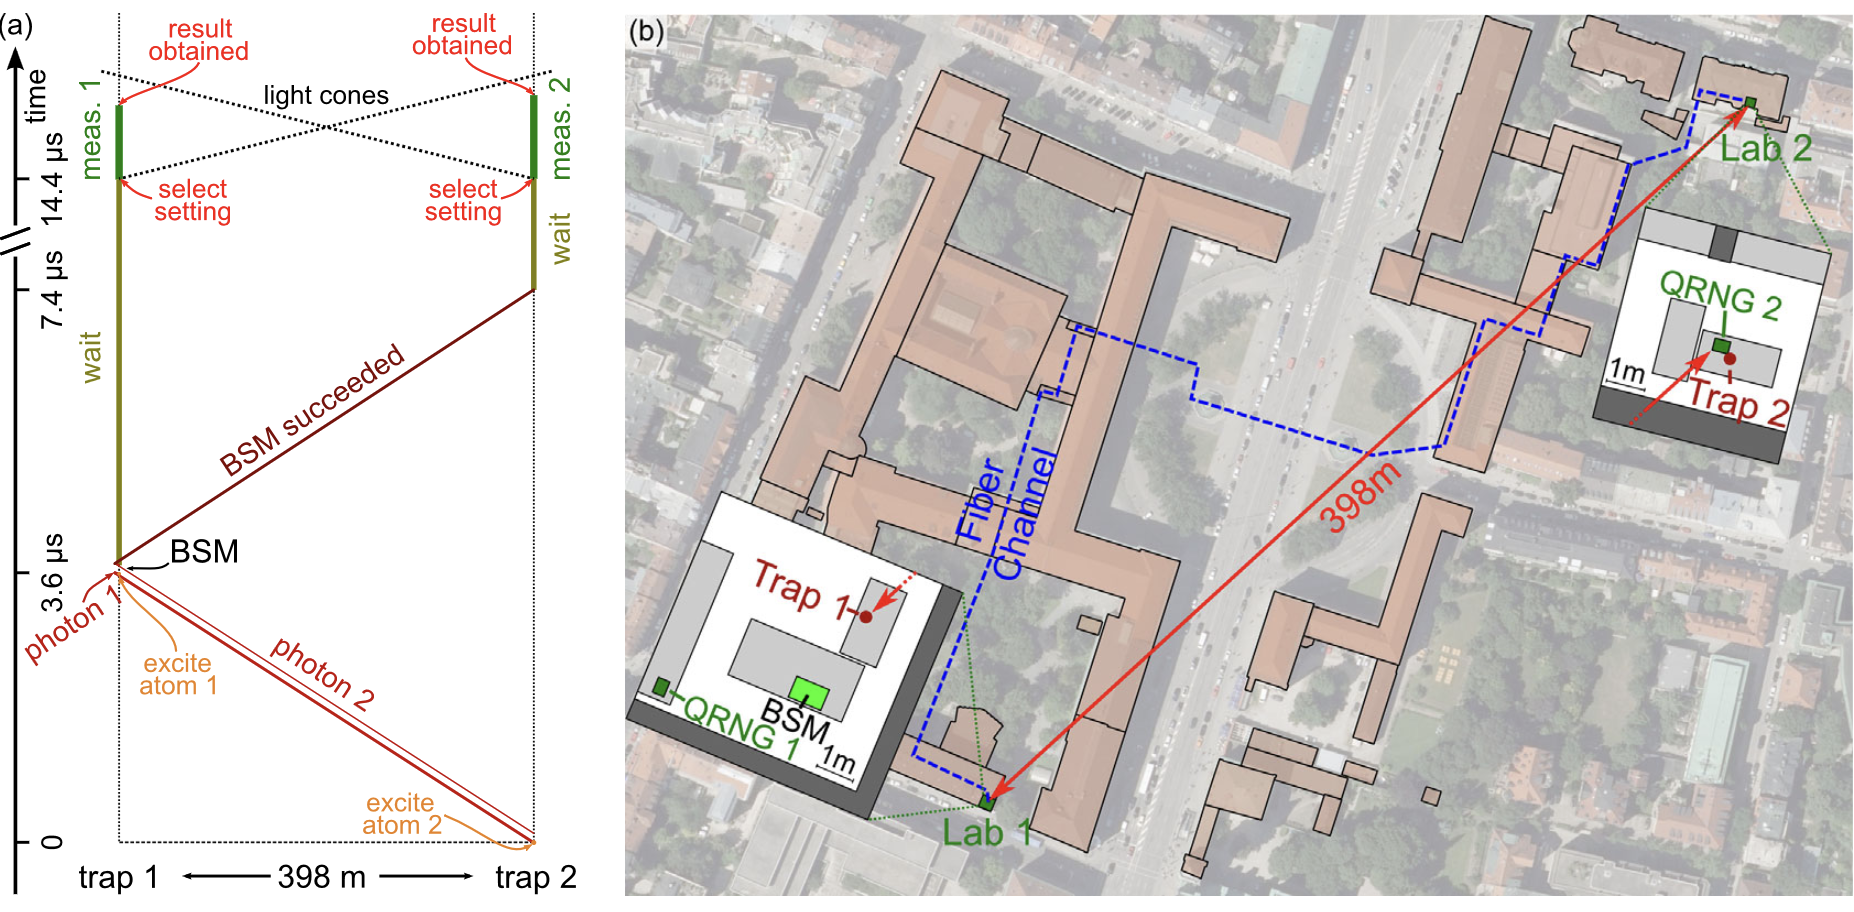
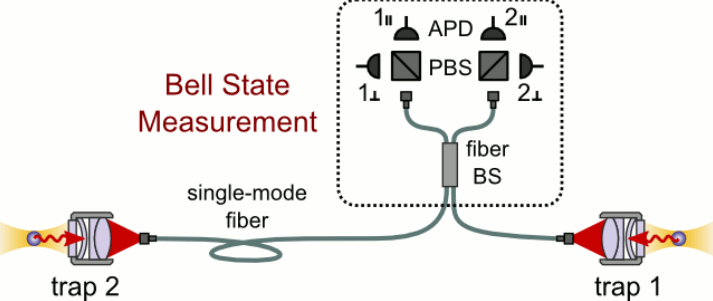

## B. A Sketch For the Project I Plan to Do
I plan to do a statistical search of the data. The experiment shows that entangled states violate the classical bound of 2, and instead are bound by the quantum bound of $2\sqrt2$. Looking at the official paper, the measured S was 2.221 ± 0.033 for each Bell state, so I wanted to explore the question "What is the probability that the violation of the CHSH inequality was random/not a significant event?" since the excess over 2 is small-ish. I also thought I could explore some if the following questions:

What is the 5-sigma threshold for a measured S to really violate the classical bound of 2? What is the probability of this happening on accident? Since the 2 labs need to have measurements of states that agree with each other, statistically, if they were just flipping coins they would get the agreeing results 50% of the time. So what is the probability that they randomly got the amoount of agreeing results that they did?

Additionally, I plan to spend a good chunk of time cleaning the data. Looking at the lab1 and lab2 files instead of the pairs.csv file, I found that some of the readings (that were included in the pairs.csv file) are marked as being excluded from the data set. So I'll have to throw out those pieces of data.





## Part 2 Downloading and plotting some data
Before I plot any data Im going to rename the columns (since theyre long) and define what they mean so I understand the structure of the data better.

In [105]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats

# added sep="\t" to have the data read with the tab separator instead of comma separator

data = pd.read_csv("Bell_2016-04-15_9_pairs.csv", sep="\t")

# the original column names are long, so I'm giving them short names
data.columns = ["time", "bell_state", "setting1", "result1",
                "setting2", "result2", "line1", "line2"]

data.head()

,time,bell_state,setting1,result1,setting2,result2,line1,line2
0,1460729997751,Psi-,0,0,0,1,0,0
1,1460730051637,Psi-,0,1,0,0,1,1
2,1460730076895,Psi+,1,0,0,1,2,2
3,1460730185215,Psi-,0,0,1,1,3,3
4,1460730195506,Psi-,1,1,1,0,4,4


In [82]:
lab1 = pd.read_csv("Bell_2016-04-15_9_lab_1.csv", sep=";");  

print(lab1["excluded from evaluation"].value_counts().to_dict())


{'no': 10201, 'yes': 17}


The columns are time, bell_state, setting1, setting2, reuslt1, and result2. 

The time column gives when the event happened (Unix time in milliseconds)

The bell-state column gives which entangled state the experiment announced, Psi+ or Psi-.

The setting1, setting 2 columns give which way (0 or 1) lab 1 and lab 2 chose to measure (the direction they measured the spin in)

the result1, result2 columns show what lab 1 and lab 2 got (0 or 1).

the line1, line2 cols show what the data was back in the original individual lab1 and lab2 files

lab 1 file has some excluded from eval pieces of data

For my first plot I'll just plot events vs. time. Im also going to show some spots where bad data got in to lab 1 to show some of the data i'll have to take out later (those are the spots in red). 

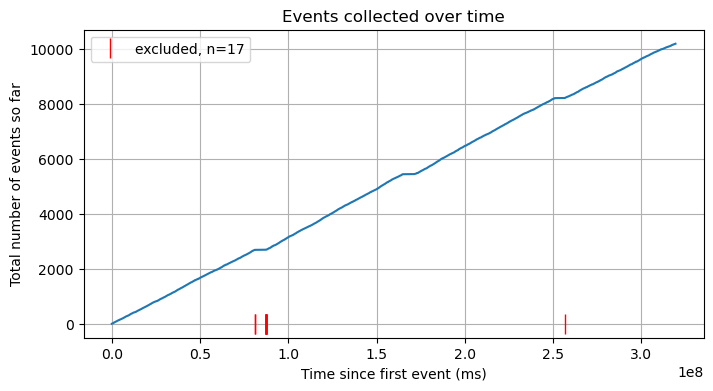

In [104]:

ms = (data["time"] - data["time"].iloc[0])   # ms since the start
bad = lab1[lab1["excluded from evaluation"] == "yes"]
t_bad = (bad["time (Unix time in ms)"].values- data["time"].iloc[0])


plt.figure(figsize=(8, 4))
plt.plot(ms, np.arange(len(data)))
plt.plot(t_bad, np.zeros_like(t_bad), "|", color="r", ms=14, label=f"excluded, n={len(bad)}")
plt.xlabel("Time since first event (ms)")
plt.ylabel("Total number of events so far")
plt.title("Events collected over time")
plt.legend()
plt.grid(True)
plt.show()


Also looking at the number of events for each combination of settings:

In [83]:
print("Number of events:", len(data))
print("Psi+ events:", np.sum(data["bell_state"] == "Psi+"))
print("Psi- events:", np.sum(data["bell_state"] == "Psi-"))

# how many events for each combination of settings?
for s1 in [0, 1]:
    for s2 in [0, 1]:
        n = np.sum((data["setting1"] == s1) & (data["setting2"] == s2))
        print(f"lab 1 setting {s1}, lab 2 setting {s2}: {n} events")

Number of events: 10201
Psi+ events: 5147
Psi- events: 5054
lab 1 setting 0, lab 2 setting 0: 2590 events
lab 1 setting 0, lab 2 setting 1: 2522 events
lab 1 setting 1, lab 2 setting 0: 2542 events
lab 1 setting 1, lab 2 setting 1: 2547 events
